# BRCA ST patient A — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **A**: patient 9769, sections A1–A6, about 0.92 µm/px (`9769_*_small`). No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=A bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
)

PATIENT = "A"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


A  n=6
9769_C1_HE_small  mpp=0.9165 µm/px  native16=14.66 µm  after rescale=8.0 µm  scale=1.8331  (ST 200 µm spot pitch (A1))
  pred exists: True
9769_C2_HE_small  mpp=0.9186 µm/px  native16=14.70 µm  after rescale=8.0 µm  scale=1.8371  (ST 200 µm spot pitch (A2))
  pred exists: True
9769_D1_HE_small  mpp=0.9218 µm/px  native16=14.75 µm  after rescale=8.0 µm  scale=1.8437  (ST 200 µm spot pitch (A3))
  pred exists: True
9769_D2_HE_small  mpp=0.9141 µm/px  native16=14.63 µm  after rescale=8.0 µm  scale=1.8282  (ST 200 µm spot pitch (A4))
  pred exists: True
9769_E1_HE_small  mpp=0.9209 µm/px  native16=14.73 µm  after rescale=8.0 µm  scale=1.8419  (ST 200 µm spot pitch (A5))
  pred exists: True
9769_E2_HE_small  mpp=0.9178 µm/px  native16=14.68 µm  after rescale=8.0 µm  scale=1.8355  (ST 200 µm spot pitch (A6))
  pred exists: True


## A — composition and spatial labels


===== A L1 =====


fraction                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
Immune                 0.692            0.667            0.663   
Stromal                0.147            0.160            0.238   
Endothelial            0.125            0.136            0.081   
Epithelial             0.036            0.037            0.019   

                                                                \
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small   
class                                                            
Immune                 0.754            0.582            0.793   
Stromal                0.145            0.228            0.099   
Endothelial            0.083            0.134            0.094   
Epithelial             0.018            0.057            0.013   

                   mean_conf                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
Immune                 0.582            0.563            0.557   
Stromal                0.430            0.445            0.467   
Endothelial            0.412            0.426            0.409   
Epithelial             0.451            0.464            0.448   

                                                                \
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small   
class                                                            
Immune                 0.584            0.534            0.592   
Stromal                0.451            0.453            0.440   
Endothelial            0.416            0.407            0.430   
Epithelial             0.450            0.466            0.444   

                           n                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
Immune               27623.0          24299.0          24520.0   
Stromal               5885.0           5810.0           8804.0   
Endothelial           4999.0           4963.0           2981.0   
Epithelial            1437.0           1332.0            692.0   

                                                                
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small  
class                                                           
Immune               26165.0          21015.0          27045.0  
Stromal               5026.0           8220.0           3375.0  
Endothelial           2886.0           4830.0           3218.0  
Epithelial             637.0           2054.0            452.0

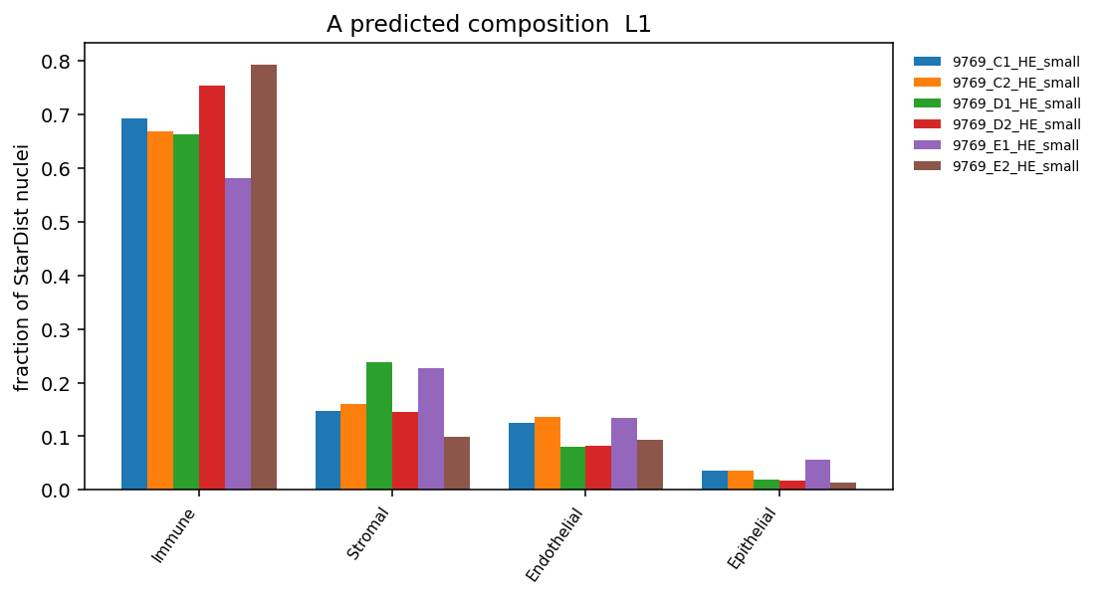

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/A_composition_L1.png

===== A L12 =====


fraction                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
T_cell                 0.807            0.795            0.812   
Stromal                0.127            0.137            0.156   
Myeloid                0.047            0.040            0.021   
Epithelial             0.006            0.010            0.004   
Endothelial            0.007            0.011            0.004   
B_Plasma               0.005            0.004            0.001   
Tumor                  0.001            0.002            0.001   

                                                                \
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small   
class                                                            
T_cell                 0.862            0.743            0.887   
Stromal                0.101            0.195            0.076   
Myeloid                0.024            0.029            0.022   
Epithelial             0.004            0.019            0.002   
Endothelial            0.004            0.007            0.007   
B_Plasma               0.003            0.004            0.005   
Tumor                  0.001            0.003            0.001   

                   mean_conf                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
T_cell                 0.481            0.483            0.491   
Stromal                0.379            0.384            0.403   
Myeloid                0.333            0.320            0.334   
Epithelial             0.413            0.416            0.423   
Endothelial            0.294            0.308            0.301   
B_Plasma               0.435            0.427            0.438   
Tumor                  0.325            0.344            0.376   

                                                                \
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small   
class                                                            
T_cell                 0.501            0.463            0.504   
Stromal                0.388            0.399            0.381   
Myeloid                0.333            0.320            0.335   
Epithelial             0.399            0.425            0.409   
Endothelial            0.299            0.299            0.306   
B_Plasma               0.442            0.409            0.432   
Tumor                  0.312            0.336            0.372   

                           n                                    \
sample      9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                            
T_cell               32228.0          28939.0          30054.0   
Stromal               5053.0           4984.0           5768.0   
Myeloid               1894.0           1455.0            784.0   
Epithelial             255.0            381.0            165.0   
Endothelial            268.0            410.0            132.0   
B_Plasma               198.0            148.0             51.0   
Tumor                   48.0             87.0             43.0   

                                                                
sample      9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small  
class                                                           
T_cell               29938.0          26841.0          30221.0  
Stromal               3492.0           7046.0           2583.0  
Myeloid                843.0           1039.0            736.0  
Epithelial             141.0            704.0             83.0  
Endothelial            147.0            246.0            253.0  
B_Plasma               104.0            147.0            171.0  
Tumor                   49.0             96.0             43.0

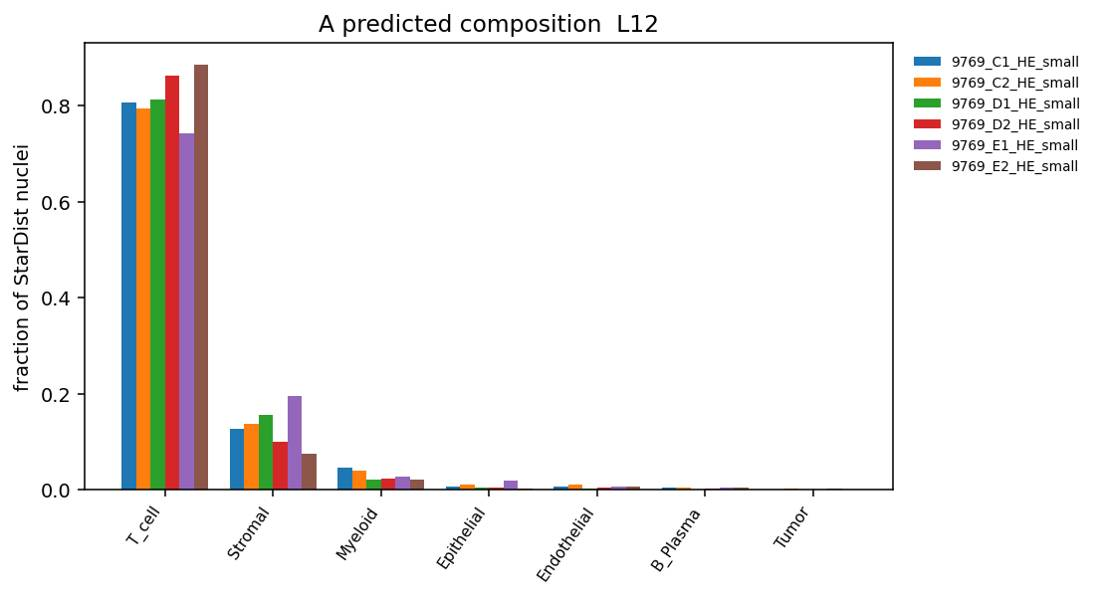

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/A_composition_L12.png

===== A L2 =====


fraction                                    \
sample            9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                                  
B_cell                       0.326            0.332            0.298   
CD4_T                        0.312            0.298            0.308   
Fibroblast                   0.167            0.136            0.234   
Stromal                      0.033            0.062            0.052   
Neutrophil                   0.077            0.076            0.042   
Endothelial                  0.045            0.059            0.029   
Epithelial                   0.012            0.011            0.007   
Tregs                        0.006            0.008            0.017   
DC                           0.013            0.004            0.005   
CD8_T                        0.007            0.009            0.006   
Injury_epithelial            0.001            0.001            0.000   
Tumor                        0.001            0.003            0.001   
Plasma                       0.000            0.000            0.000   
DCIS                         0.000              NaN            0.000   
Macrophage                     NaN              NaN              NaN   
Myoepithelial                  NaN            0.000            0.000   

                                                                      \
sample            9769_D2_HE_small 9769_E1_HE_small 9769_E2_HE_small   
class                                                                  
B_cell                       0.390            0.339            0.470   
CD4_T                        0.333            0.250            0.306   
Fibroblast                   0.136            0.180            0.092   
Stromal                      0.049            0.091            0.039   
Neutrophil                   0.035            0.031            0.028   
Endothelial                  0.031            0.059            0.042   
Epithelial                   0.005            0.018            0.003   
Tregs                        0.006            0.005            0.002   
DC                           0.005            0.006            0.004   
CD8_T                        0.008            0.013            0.012   
Injury_epithelial            0.000            0.003            0.000   
Tumor                        0.002            0.003            0.001   
Plasma                       0.000            0.001            0.000   
DCIS                         0.000            0.000            0.000   
Macrophage                   0.000            0.000            0.000   
Myoepithelial                  NaN            0.000            0.000   

                         mean_conf                                    \
sample            9769_C1_HE_small 9769_C2_HE_small 9769_D1_HE_small   
class                                                                  
B_cell                       0.357            0.332            0.334   
CD4_T                        0.265            0.266            0.266   
Fibroblast                   0.247            0.249            0.264   
Stromal                      0.280            0.308            0.299   
Neutrophil                   0.225            0.221            0.209   
Endothelial                  0.213            0.228            0.213   
Epithelial                   0.267            0.309            0.278   
Tregs                        0.227            0.242            0.246   
DC                           0.247            0.227            0.243   
CD8_T                        0.219            0.215            0.223   
Injury_epithelial            0.263            0.244            0.227   
Tumor                        0.239            0.246            0.287   
Plasma                       0.189            0.193            0.211   
DCIS                         0.198              NaN            0.237   
Macrophage                     NaN              NaN             

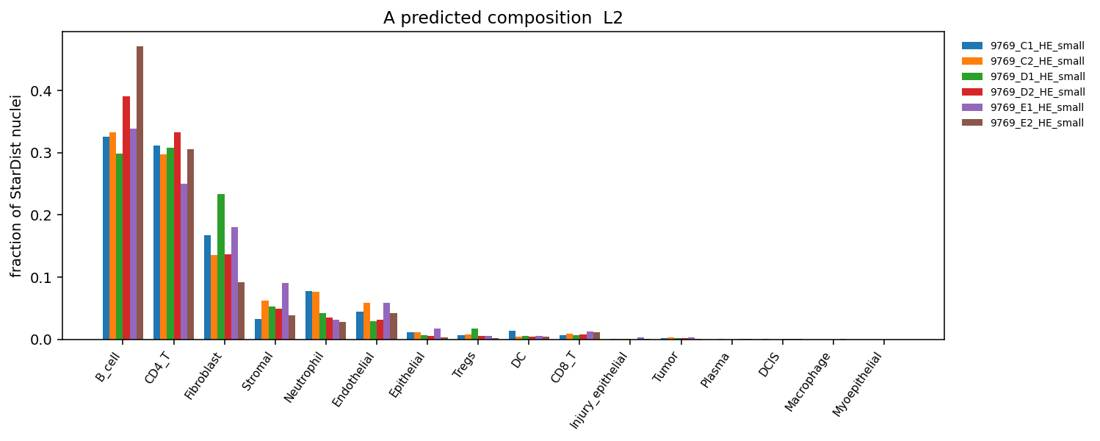

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/A_composition_L2.png
9769_C1_HE_small


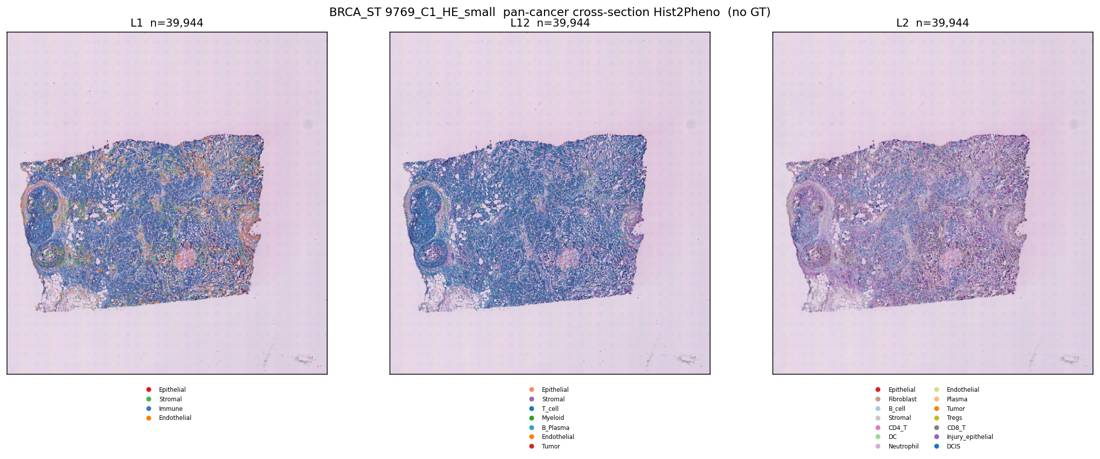

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C1_HE_small_spatial_L1_L12_L2.png
9769_C2_HE_small


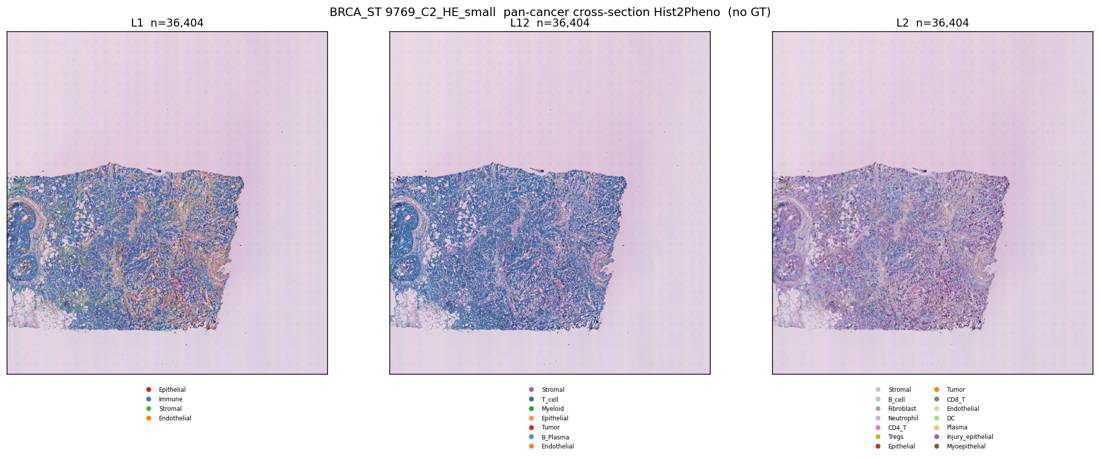

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C2_HE_small_spatial_L1_L12_L2.png
9769_D1_HE_small


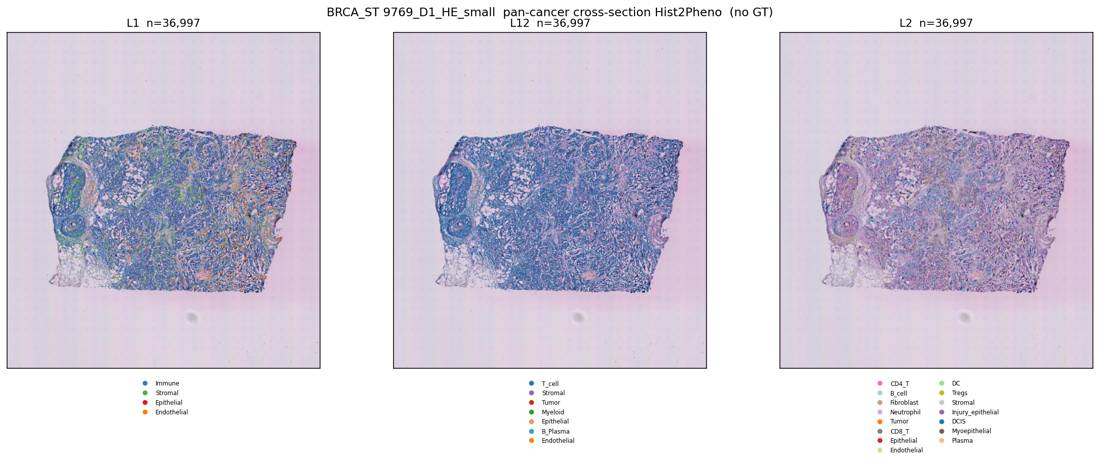

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D1_HE_small_spatial_L1_L12_L2.png
9769_D2_HE_small


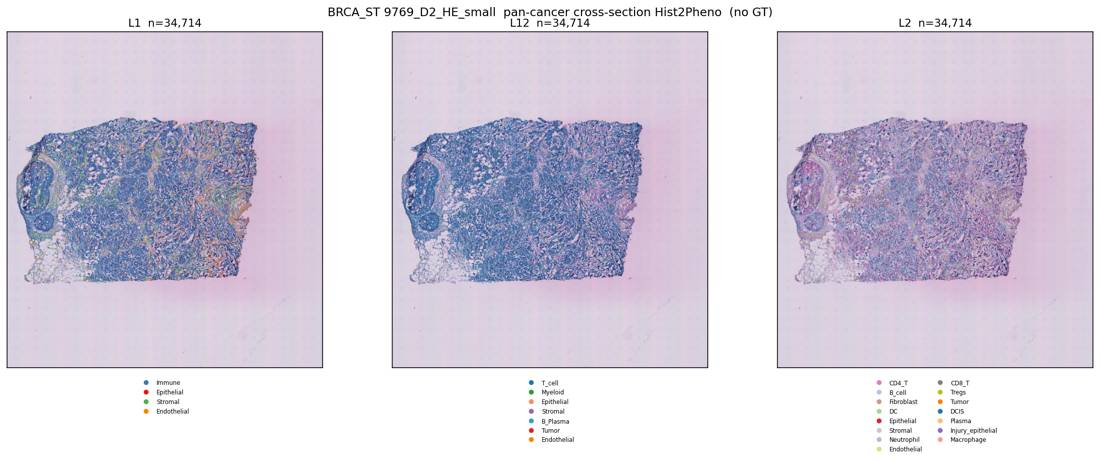

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D2_HE_small_spatial_L1_L12_L2.png
9769_E1_HE_small


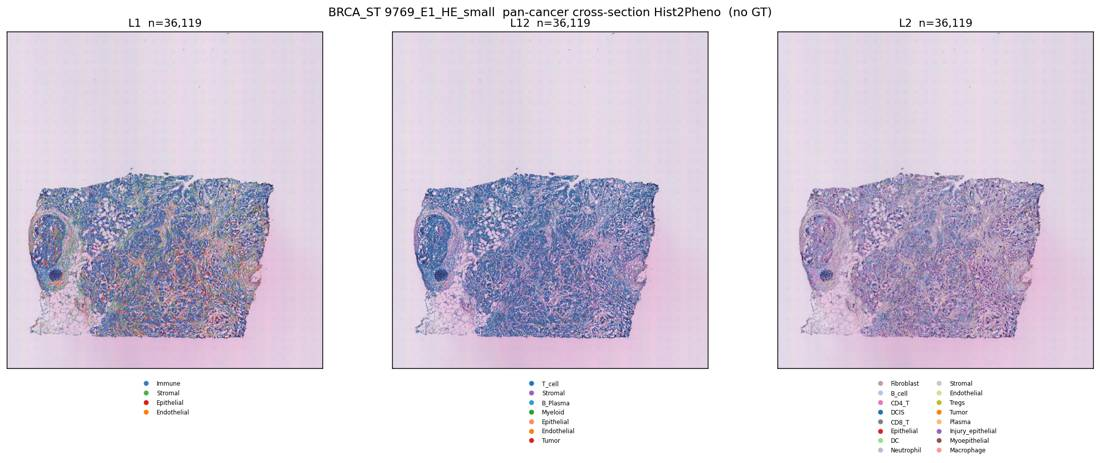

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E1_HE_small_spatial_L1_L12_L2.png
9769_E2_HE_small


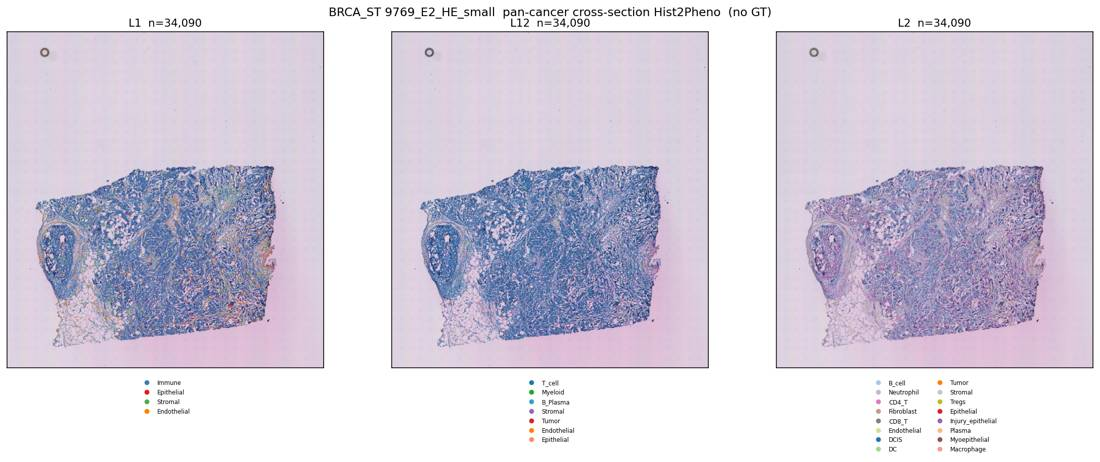

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E2_HE_small_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    if SAVE_FIGURES:
        out = fig_dir / f"{PATIENT}_composition_{head}.png"
        fig.savefig(out, dpi=DPI, bbox_inches="tight")
        print(out)
    display(fig)
    plt.close(fig)

for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## A — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/9769_C1_HE_small/9769_C1_HE_small_l2_probs.npz  (39944, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/9769_C1_HE_small/9769_C1_HE_small_niche_indices.h5ad  n=39,944
  TLS hotspot: {'n_cells_total': 39944, 'n_candidate_cells': 1998, 'fraction_candidate': 0.050020028039254955, 'max_tls_spatial': 0.2679090511840785, 'mean_tls_spatial_candidate': 0.22480886138508452, 'centroid_x': 2164.0535035453163, 'centroid_y': 4122.466337309943}
  mean TLS=0.589  TLS_spatial=0.161  SRI=10.754  TNI=17.930
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/9769_C2_HE_small/9769_C2_HE_small_l2_probs.npz  (36404, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/9769_C2_HE_small/9769_C2_HE_small_niche_indices.h5ad  n=36,404
  TLS hotspot: {'n_cells_total': 36404, 'n_candidate_cells

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,9769_C1_HE_small,39944,0.589,0.605,0.879,0.986,0.161,0.166,0.216,0.268,0.751,0.739,0.115,0.206,0.202,0.795
1,9769_C2_HE_small,36404,0.570,0.586,0.863,0.981,0.152,0.155,0.199,0.242,0.682,0.662,0.114,0.205,0.183,0.764
2,9769_D1_HE_small,36997,0.578,0.586,0.860,0.984,0.156,0.159,0.199,0.240,0.655,0.638,0.114,0.205,0.185,0.762
3,9769_D2_HE_small,34714,0.620,0.640,0.881,0.979,0.162,0.166,0.203,0.237,0.653,0.618,0.093,0.171,0.187,0.785
4,9769_E1_HE_small,36119,0.544,0.554,0.850,0.987,0.146,0.149,0.196,0.255,0.682,0.664,0.129,0.228,0.181,0.756
5,9769_E2_HE_small,34090,0.645,0.670,0.891,0.987,0.165,0.170,0.205,0.239,0.631,0.579,0.058,0.109,0.186,0.771


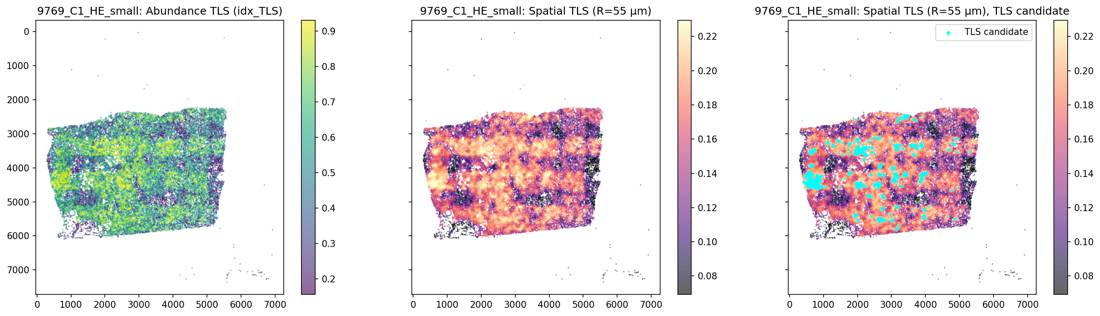

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C1_HE_small_TLS_abundance_vs_spatial.png


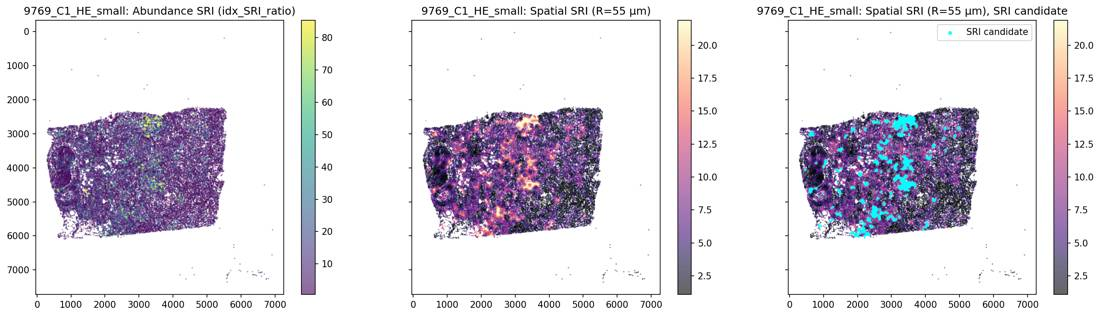

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C1_HE_small_SRI_abundance_vs_spatial.png


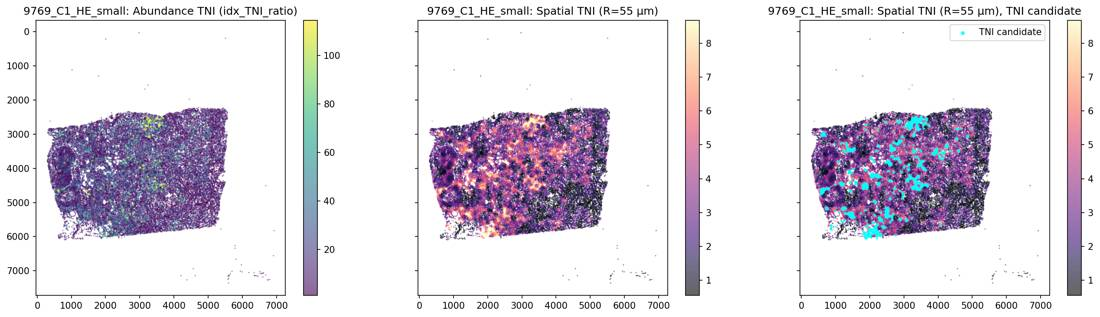

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C1_HE_small_TNI_abundance_vs_spatial.png


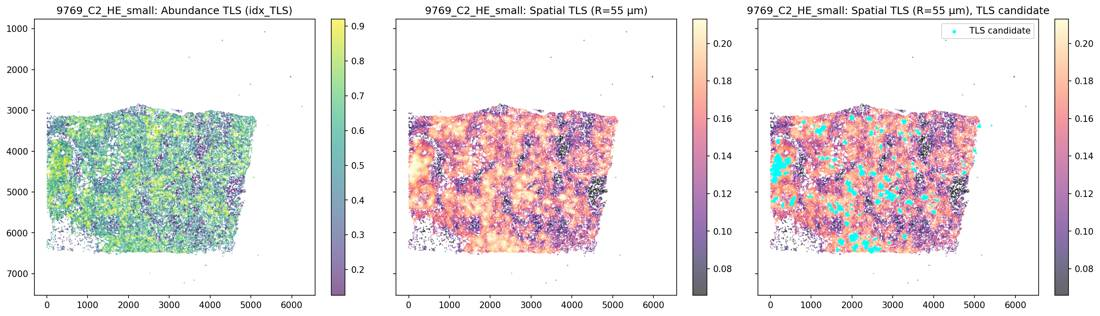

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C2_HE_small_TLS_abundance_vs_spatial.png


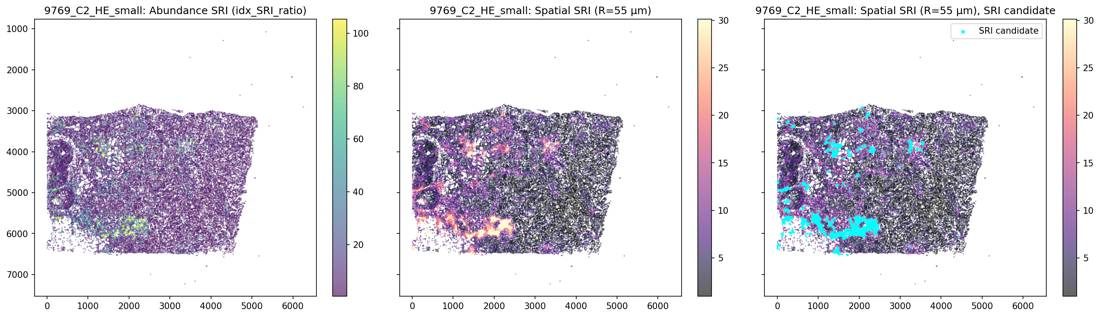

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C2_HE_small_SRI_abundance_vs_spatial.png


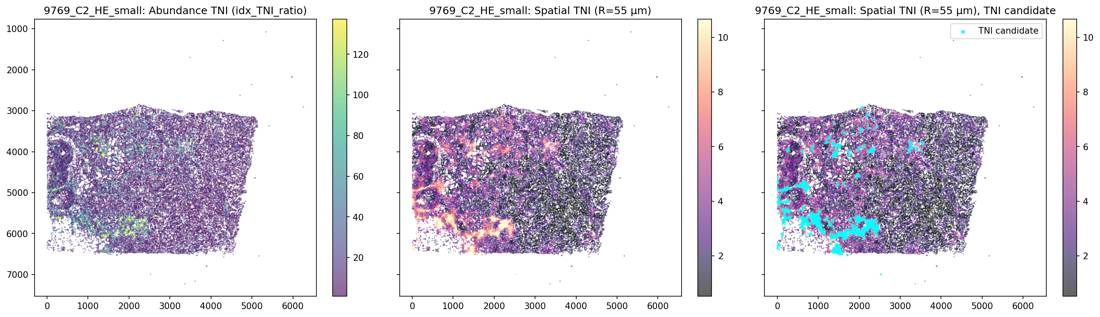

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_C2_HE_small_TNI_abundance_vs_spatial.png


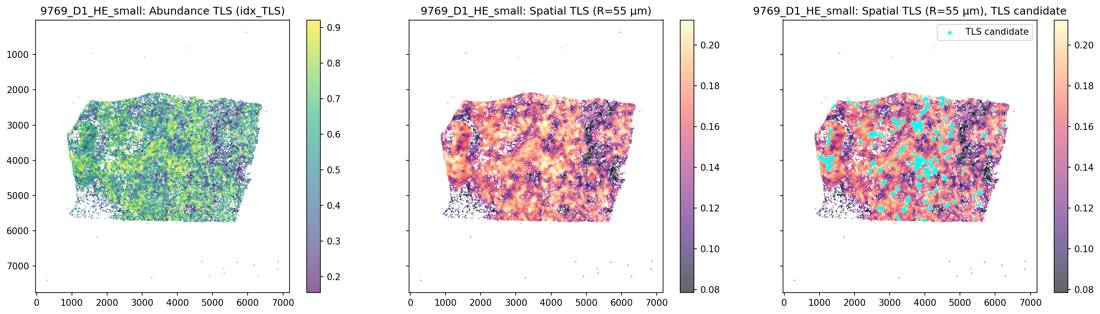

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D1_HE_small_TLS_abundance_vs_spatial.png


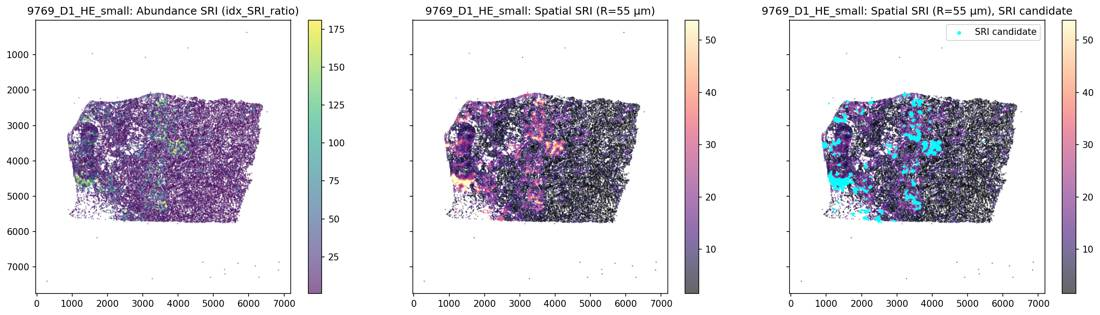

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D1_HE_small_SRI_abundance_vs_spatial.png


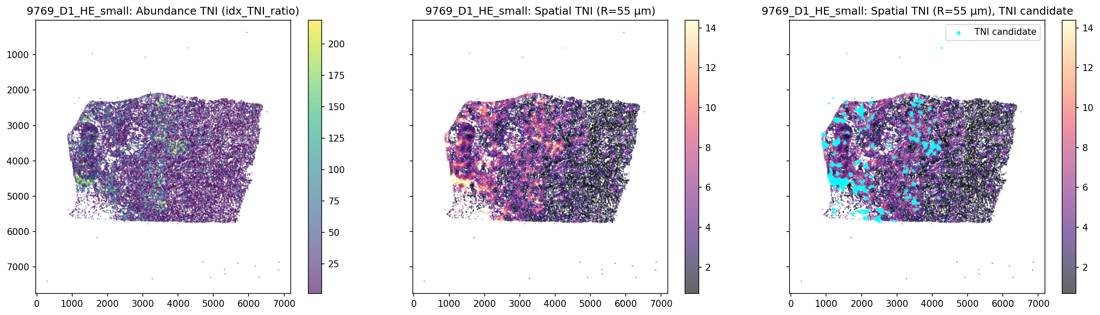

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D1_HE_small_TNI_abundance_vs_spatial.png


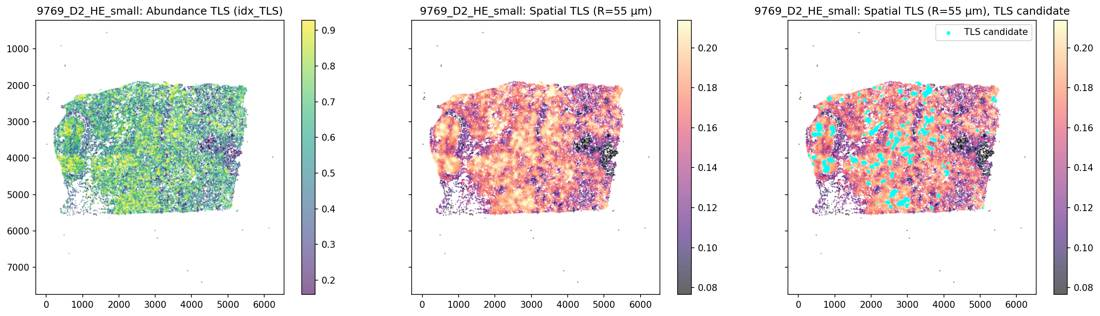

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D2_HE_small_TLS_abundance_vs_spatial.png


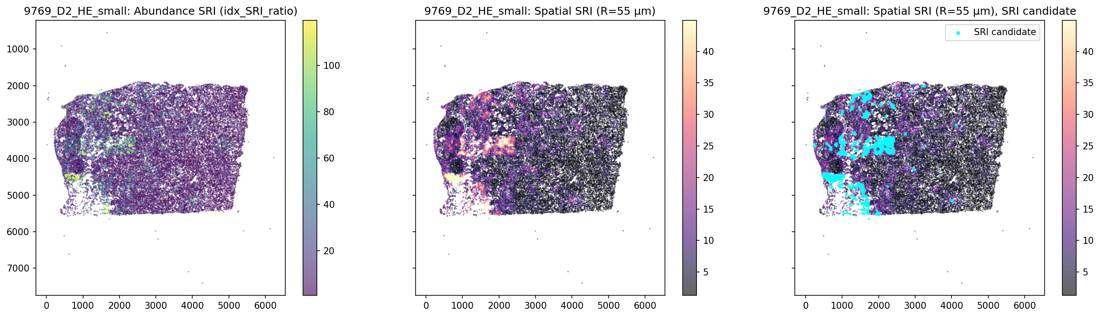

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D2_HE_small_SRI_abundance_vs_spatial.png


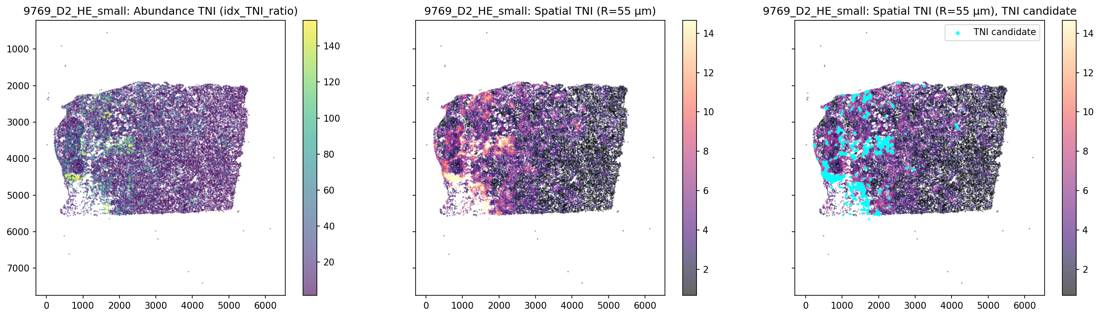

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_D2_HE_small_TNI_abundance_vs_spatial.png


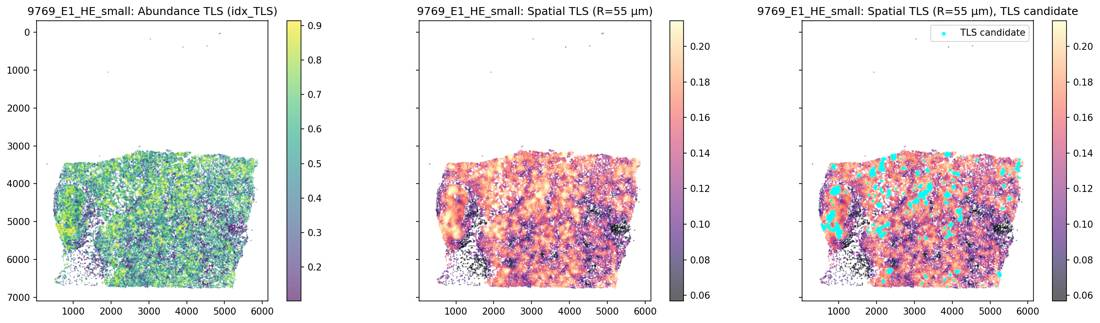

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E1_HE_small_TLS_abundance_vs_spatial.png


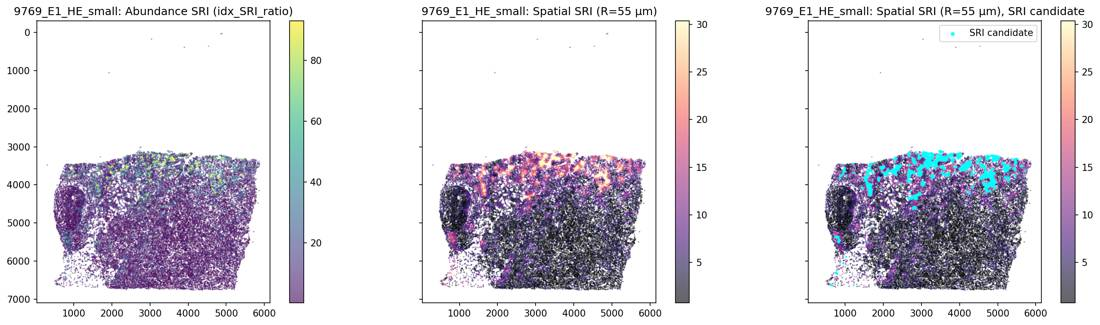

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E1_HE_small_SRI_abundance_vs_spatial.png


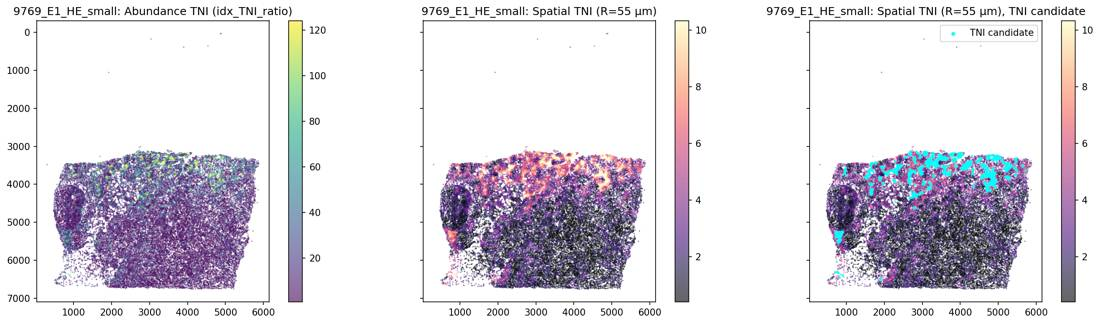

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E1_HE_small_TNI_abundance_vs_spatial.png


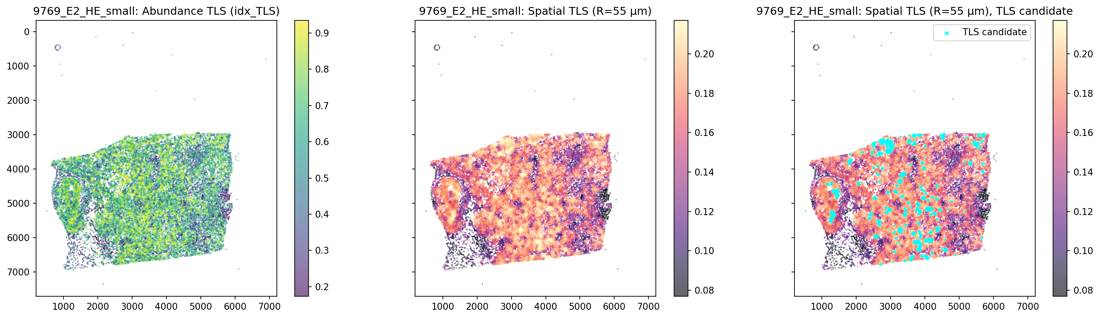

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E2_HE_small_TLS_abundance_vs_spatial.png


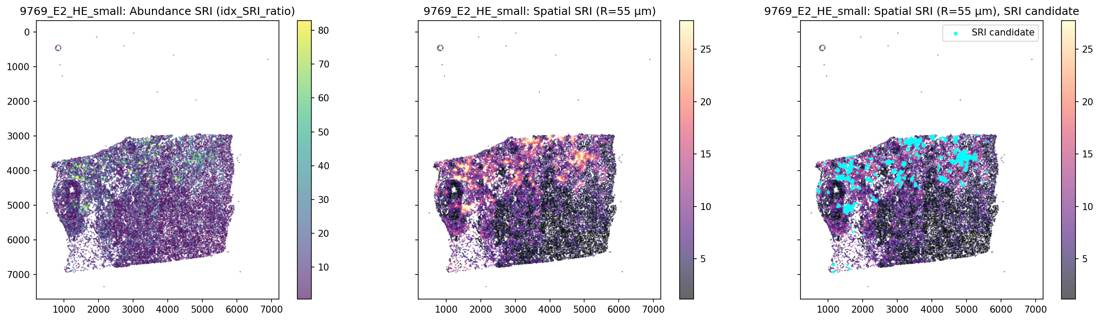

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E2_HE_small_SRI_abundance_vs_spatial.png


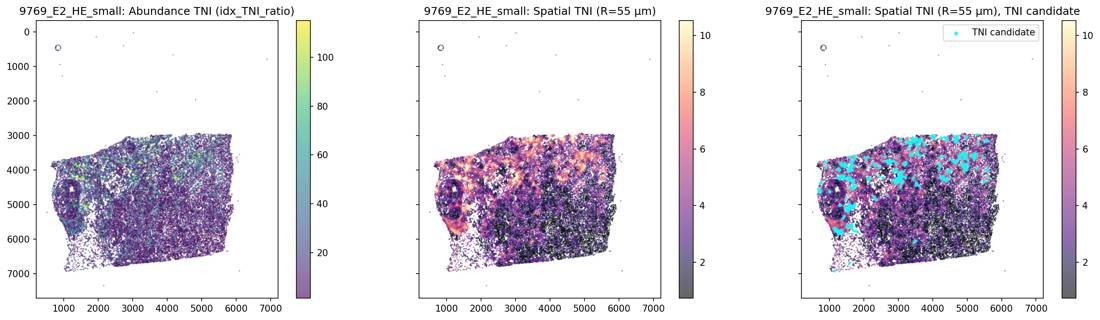

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/9769_E2_HE_small_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
